# Feature and Ensemble Audit

Measured public ROC AUC: **0.96204**. The selected prediction reproduces [Hanif Noer Rofiq's public control](https://www.kaggle.com/code/hanifnoerrofiq/agentic-ensemble), with exact content-hash and ID checks. Credit belongs to Hanif and the public model authors cited upstream.

The foundation table records our actual account submissions with fixed 1% additions, each submitted once. It is a measured experiment log, not CV and not a rerun of the private foundation models. The selected public prediction is recomputed below. An optional CPU experiment reproduces the data-processing comparison.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata

RUN_FEATURE_STUDY = False
SOURCE_SHA = 'f02e97aa6b454f7b2897ffdf5873830b5f89ded5f0f18cd04f4013c65e68fbf4'
EXPECTED_SHA = '307da3105f0b0833e06451818da0eba3f111d85644f403d2ccfb3555425d5df4'
root = Path('/kaggle/input')
sample = next(p for p in root.rglob('sample_submission.csv') if 'playground-series-s6e10' in str(p))
ids = pd.read_csv(sample).id.to_numpy()
paths = [p for p in root.rglob('submission.csv') if 'agentic-ensemble' in str(p)]
paths = [p for p in paths if hashlib.sha256(p.read_bytes()).hexdigest() == SOURCE_SHA]
assert len(paths) == 1, 'Upstream prediction changed'
frame = pd.read_csv(paths[0])
assert frame.id.is_unique and set(frame.id) == set(ids)
p = frame.set_index('id').loc[ids].satisfaction.to_numpy()
assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
p = (rankdata(p) - 0.5) / len(p)
submission = pd.DataFrame({'id': ids, 'satisfaction': p})
submission.to_csv('submission.csv', index=False, float_format='%.12f')
assert hashlib.sha256(Path('submission.csv').read_bytes()).hexdigest() == EXPECTED_SHA
print(f'{len(submission):,} rows. Exact scored public prediction reproduced.')


299,844 rows. Exact scored public prediction reproduced.


,variant,public_AUC,submission_reference,delta
0,Control,0.96204,57401016,+0.00000
1,+1% Kumo,0.96203,57401142,-0.00001
2,+1% TabICL,0.96203,57401957,-0.00001
3,+1% each,0.96203,57401965,-0.00001


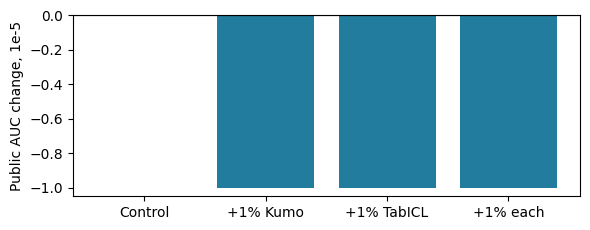

Recorded Kaggle submissions. Public values are rounded; no private-set gain is claimed.


In [2]:
records = pd.DataFrame([{'variant': 'Control', 'public_AUC': 0.96204, 'submission_reference': 57401016}, {'variant': '+1% Kumo', 'public_AUC': 0.96203, 'submission_reference': 57401142}, {'variant': '+1% TabICL', 'public_AUC': 0.96203, 'submission_reference': 57401957}, {'variant': '+1% each', 'public_AUC': 0.96203, 'submission_reference': 57401965}])
records['delta'] = records.public_AUC - records.public_AUC.iloc[0]
display(records.style.format({'public_AUC': '{:.5f}', 'delta': '{:+.5f}'}))
fig, ax = plt.subplots(figsize=(6, 2.4))
ax.bar(records.variant, records.delta * 1e5, color='#227c9d')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Public AUC change, 1e-5')
plt.tight_layout()
plt.show()
records.to_csv('measured_submissions.csv', index=False)
print('Recorded Kaggle submissions. Public values are rounded; no private-set gain is claimed.')


## Recompute the feature study

Set `RUN_FEATURE_STUDY = True` to train three CPU CatBoost models on the same 100,000 fit rows, with separate stopping and 56,193 development rows. Route/target maps use reference rows only; training encodings use five inner folds. Exact original-data overlaps with competition rows are excluded. The development split was reused during research.

Our run, with the same original-data teacher in all three views: raw **0.958131**, hierarchical **0.959118**, semantic **0.959316**. The semantic view adds categorical copies of ratings/distance, segment categories and rating summaries. This solo gain did not establish an ensemble gain: the matched OOF meta-stack changed from **0.9613708** to **0.9613748**, with paired 95% interval **[-0.0000422, +0.0000504]** for the difference. We did not promote it to full training.

In [3]:
if RUN_FEATURE_STUDY:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'catboost==1.2.8', 'xgboost==3.4.1', 'scikit-learn==1.6.1'])


In [4]:
if RUN_FEATURE_STUDY:
    import os, json, time, random, hashlib, gc, platform
    from pathlib import Path
    import numpy as np
    import pandas as pd
    import xgboost as xgb
    from sklearn.metrics import roc_auc_score
    from importlib.metadata import version
    SEED = 42
    random.seed(SEED)
    np.random.seed(SEED)
    OUT = Path('/kaggle/working/feature_study')
    OUT.mkdir(exist_ok=True)
    DATA = next(p.parent for p in Path('/kaggle/input').rglob('train.csv') if 'playground-series-s6e10' in str(p))
    train = pd.read_csv(DATA/'train.csv')
    test = pd.read_csv(DATA/'test.csv')
    TARGET = 'satisfaction'
    CATS = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
    FEATS = [c for c in train if c not in ['id', TARGET]]
    RATINGS = [c for c in FEATS if c not in CATS + ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']]
    y = train[TARGET].astype(int).to_numpy()
    X = train[FEATS].copy()
    row_hash = pd.util.hash_pandas_object(X, index=False).to_numpy()
    unique_hash, inverse = np.unique(row_hash, return_inverse=True)
    u = np.random.default_rng(SEED).random(len(unique_hash))[inverse]
    parts = {'fit': np.flatnonzero(u >= .28), 'stop': np.flatnonzero((u >= .23)&(u < .28)),
             'dev': np.flatnonzero((u >= .15)&(u < .23)), 'audit': np.flatnonzero(u < .15)}
    assert sum(map(len, parts.values())) == len(train)
    for a in parts:
     for b in parts:
      if a < b: assert not np.intersect1d(row_hash[parts[a]], row_hash[parts[b]]).size
    split = pd.DataFrame({'id':train.id, 'part':np.select([u<.15,u<.23,u<.28],['audit','dev','stop'],default='fit'), 'feature_hash':row_hash})
    split.to_csv(OUT/'split_manifest.csv',index=False)
    DATA_HASH = hashlib.sha256((DATA/'train.csv').read_bytes()).hexdigest()
    SPLIT_HASH = hashlib.sha256((OUT/'split_manifest.csv').read_bytes()).hexdigest()
    env = {p:version(p) for p in ['numpy','pandas','scikit-learn','xgboost']}
    (OUT/'environment.json').write_text(json.dumps({'seed':SEED,'packages':env,'data_sha256':DATA_HASH,'split_sha256':SPLIT_HASH},indent=2))
    fit_idx, stop_idx, dev_idx, audit_idx = (parts[k] for k in ['fit','stop','dev','audit'])
    print('SPLIT', {k:len(v) for k,v in parts.items()}, flush=True)
    print('DUPLICATE_FEATURE_ROWS',len(X)-len(unique_hash),'CONFLICTING_GROUPS',int(pd.DataFrame({'h':row_hash,'y':y}).groupby('h').y.nunique().gt(1).sum()),flush=True)
    print('ENV',env,flush=True)

In [5]:
if RUN_FEATURE_STUDY:
    def numeric_frame(f):
        r = f.copy()
        for c in CATS:
            r[c] = r[c].map({'Female':0,'Male':1,'Loyal Customer':0,'disloyal Customer':1,
                             'Personal Travel':0,'Business travel':1,'Eco':0,'Eco Plus':1,'Business':2}).astype('float32')
        r.columns = ['f'+str(i) for i in range(len(r.columns))]
        return r.astype('float32')

    import kagglehub
    original_path = Path(kagglehub.dataset_download('arseniyshutko/binary-aviation-satisfaction-129k'))
    original = pd.concat([pd.read_csv(p) for p in original_path.rglob('*.csv')],ignore_index=True)
    original.columns = original.columns.str.strip()
    label_map = {'true':1,'false':0,'1':1,'0':0,'satisfied':1,'neutral or dissatisfied':0}
    original[TARGET] = original[TARGET].astype(str).str.strip().str.lower().map(label_map)
    assert original[TARGET].notna().all() and original[TARGET].nunique()==2
    original[TARGET] = original[TARGET].astype(int)
    original = original[FEATS+[TARGET]].drop_duplicates().reset_index(drop=True)
    joined = pd.concat([X,test[FEATS],original[FEATS]],ignore_index=True)
    for col in FEATS:
        if col not in CATS: joined[col] = pd.to_numeric(joined[col],errors='coerce').astype('float64')
        else: joined[col] = joined[col].astype(str).str.strip()
    all_hash = pd.util.hash_pandas_object(joined,index=False).to_numpy()
    competition_hash = all_hash[:len(X)+len(test)]
    original_hash = all_hash[len(X)+len(test):]
    keep = ~np.isin(original_hash,competition_hash)
    print('ORIGINAL_AUDIT',json.dumps({'loaded':len(original),'excluded_exact_overlap':int((~keep).sum()),'retained':int(keep.sum()),'source':'arseniyshutko/binary-aviation-satisfaction-129k'}),flush=True)
    original = original.loc[keep].reset_index(drop=True)
    original.to_csv(OUT/'original_clean.csv',index=False)
    original_cfg=dict(n_estimators=600,learning_rate=.05,max_depth=8,subsample=.8,colsample_bytree=.5,
                      device='cpu',tree_method='hist',random_state=SEED,n_jobs=4)
    original_model=xgb.XGBClassifier(**original_cfg)
    original_model.fit(numeric_frame(original[FEATS]),original[TARGET])
    original_model.save_model(OUT/'original_teacher.json')
    def original_teacher(df):
        return original_model.predict_proba(numeric_frame(df[FEATS]))[:,1]
    (OUT/'original_audit.json').write_text(json.dumps({'source':'arseniyshutko/binary-aviation-satisfaction-129k','source_path':str(original_path),'retained_rows':len(original),'excluded_exact_overlap':int((~keep).sum()),'parameters':original_cfg},indent=2))


In [6]:
if RUN_FEATURE_STUDY:
    """Fold-local representations. Targets enter only through nested cross-fitted maps."""
    class ProcessingView:
        def __init__(self, kind, feats, cats, ratings, teacher=None, original_rates=None):
            self.kind=kind; self.feats=list(feats); self.cats=list(cats); self.ratings=list(ratings)
            self.teacher=teacher; self.original_rates=original_rates

        def keys(self, frame):
            def join(columns):
                result=frame[columns[0]].astype(str)
                for col in columns[1:]:result=result+'|'+frame[col].astype(str)
                return result.reset_index(drop=True)
            route=frame['Flight Distance'].astype(str).reset_index(drop=True)
            segment=join(['Type of Travel','Customer Type','Class'])
            return pd.DataFrame({'route':route,
                'distance10':(frame['Flight Distance']//10).astype(str).to_numpy(),
                'segment':segment,'route_class':route+'|'+frame['Class'].astype(str).to_numpy(),
                'route_travel':route+'|'+frame['Type of Travel'].astype(str).to_numpy(),
                'segment_age':segment+'|'+(frame['Age']//10).astype(str).to_numpy(),
                'segment_boarding':segment+'|'+frame['Online boarding'].astype(str).to_numpy()})

        def fit(self, frame, labels, groups):
            self.reference=frame[self.feats].copy(); self.labels=np.asarray(labels)
            self.groups=np.asarray(groups); self.prior=float(self.labels.mean())
            self.route_count=frame['Flight Distance'].value_counts()
            self.route_tables={c:frame.groupby('Flight Distance')[c].agg(['mean','std'])
                               for c in ['Age','Online boarding','Inflight wifi service','Seat comfort']}
            self.global_stats={c:(float(frame[c].mean()),float(frame[c].std())) for c in self.route_tables}
            self.frequency={c:frame[c].value_counts(normalize=True,dropna=False) for c in ['Age','Flight Distance']}
            self.maps=self.target_maps(self.keys(frame),self.labels)
            return self

        def target_maps(self, keys, labels):
            prior=float(np.mean(labels)); maps={}
            for col in keys:
                stats=pd.DataFrame({'key':keys[col].to_numpy(),'target':np.asarray(labels)}).groupby('key').target.agg(['sum','count'])
                maps[col]=(stats,prior)
            return maps

        def encode_targets(self, keys, maps):
            values={}; prior=next(iter(maps.values()))[1]
            parents={'route':'distance10','route_class':'route','route_travel':'route',
                     'segment_age':'segment','segment_boarding':'segment'}
            order=['distance10','segment','route','route_class','route_travel','segment_age','segment_boarding']
            for col in order:
                stats,_=maps[col]
                count=keys[col].map(stats['count']).fillna(0).to_numpy()
                total=keys[col].map(stats['sum']).fillna(0).to_numpy()
                parent=values['hier_te_'+parents[col]] if col in parents else np.full(len(keys),prior)
                values['hier_te_'+col]=((total+20*parent)/(count+20)).astype(np.float32)
                if col in ['route','route_class','route_travel']:
                    values['hier_logcount_'+col]=np.log1p(count).astype(np.float32)
            return pd.DataFrame(values)

        def static(self, frame):
            out=frame[self.feats].reset_index(drop=True).copy()
            if self.kind=='raw':return out
            if self.kind=='semantic':
                for col in self.ratings+['Flight Distance']:
                    out['category_'+col]=out[col].fillna(-1).astype(str).astype('category')
                out['segment_category']=(out['Type of Travel'].astype(str)+'|'+out['Customer Type'].astype(str)+'|'+out['Class'].astype(str)).astype('category')
                out['zero_rating_count']=(out[self.ratings]==0).sum(axis=1).astype(np.float32)
                positive=out[self.ratings].replace(0,np.nan)
                out['positive_rating_mean']=positive.mean(axis=1).astype(np.float32)
                out['positive_rating_std']=positive.std(axis=1).astype(np.float32)
            else:
                counts=out['Flight Distance'].map(self.route_count).fillna(0).to_numpy()
                out['route_logcount']=np.log1p(counts).astype(np.float32)
                for col,stats in self.route_tables.items():
                    global_mean,global_std=self.global_stats[col]
                    mean=out['Flight Distance'].map(stats['mean']).fillna(global_mean).to_numpy()
                    mean=(counts*mean+20*global_mean)/(counts+20)
                    scale=out['Flight Distance'].map(stats['std']).fillna(global_std).to_numpy()
                    scale=np.maximum(scale,.25)
                    out['shrunk_route_'+col]=mean.astype(np.float32)
                    out['route_z_'+col]=((out[col].to_numpy()-mean)/scale).astype(np.float32)
                for col,mapping in self.frequency.items():
                    out['frequency_'+col]=out[col].map(mapping).fillna(0).astype(np.float32)
            for col in ['Departure Delay in Minutes','Arrival Delay in Minutes']:
                out['log_'+col]=np.log1p(out[col].fillna(0).clip(lower=0)).astype(np.float32)
            out['delay_difference']=(out['Arrival Delay in Minutes'].fillna(0)-out['Departure Delay in Minutes'].fillna(0)).astype(np.float32)
            if self.teacher is not None:
                p=np.clip(self.teacher(frame),1e-6,1-1e-6)
                out['original_probability']=p.astype(np.float32)
                out['original_logit']=np.log(p/(1-p)).astype(np.float32)
            if self.kind=='hier_original' and self.original_rates is not None:
                for col,(mapping,prior) in self.original_rates.items():
                    out['original_rate_'+col]=frame[col].map(mapping).fillna(prior).to_numpy(dtype=np.float32)
            return out

        def transform(self, frame):
            out=self.static(frame)
            if self.kind.startswith('hier'):
                out=pd.concat([out,self.encode_targets(self.keys(frame),self.maps)],axis=1)
            return out

        def fit_transform(self, frame, labels, groups):
            self.fit(frame,labels,groups)
            out=self.static(frame)
            if self.kind.startswith('hier'):
                keys=self.keys(frame); folds=(self.groups%np.uint64(5)).astype(int)
                encoded=None
                for fold in range(5):
                    take=np.flatnonzero(folds!=fold); query=np.flatnonzero(folds==fold)
                    if not len(query):continue
                    if not len(take):raise ValueError('Inner fold has no reference labels')
                    values=self.encode_targets(keys.iloc[query],self.target_maps(keys.iloc[take],self.labels[take]))
                    if encoded is None:encoded=pd.DataFrame(index=np.arange(len(frame)),columns=values.columns,dtype=np.float32)
                    encoded.iloc[query]=values.to_numpy()
                assert encoded is not None and np.isfinite(encoded.to_numpy()).all()
                out=pd.concat([out,encoded],axis=1)
            assert 'id' not in out and 'satisfaction' not in out
            return out


In [7]:
if RUN_FEATURE_STUDY:
    from catboost import CatBoostClassifier
    from sklearn.model_selection import train_test_split
    positions,_=train_test_split(np.arange(len(fit_idx)),train_size=100000,stratify=y[fit_idx],random_state=107)
    reference=fit_idx[positions]
    assert not np.intersect1d(row_hash[reference],row_hash[dev_idx]).size
    assert not np.intersect1d(row_hash[reference],row_hash[stop_idx]).size
    np.save(OUT/'dev_ids.npy',train.id.iloc[dev_idx].to_numpy())
    np.save(OUT/'reference_ids.npy',train.id.iloc[reference].to_numpy())
    rates={col:(original.groupby(col,dropna=False)[TARGET].mean(),float(original[TARGET].mean())) for col in FEATS}
    results=[]
    for kind in ['raw_teacher','hier','semantic']:
        started=time.perf_counter()
        view=ProcessingView('raw' if kind=='raw_teacher' else kind,FEATS,CATS,RATINGS,original_teacher,rates)
        a=view.fit_transform(X.iloc[reference],y[reference],row_hash[reference])
        b=view.transform(X.iloc[stop_idx]);c=view.transform(X.iloc[dev_idx]);del view
        if kind=='raw_teacher':
            for frame,raw in zip([a,b,c],[X.iloc[reference],X.iloc[stop_idx],X.iloc[dev_idx]]):
                probability=np.clip(original_teacher(raw),1e-6,1-1e-6)
                frame['original_probability']=probability.astype(np.float32)
                frame['original_logit']=np.log(probability/(1-probability)).astype(np.float32)
        categorical=[col for col in a if col in CATS or not pd.api.types.is_numeric_dtype(a[col])]
        for frame in [a,b,c]:
            for col in categorical:frame[col]=frame[col].astype(str).fillna('__NA__')
            for col in frame.columns.difference(categorical):frame[col]=pd.to_numeric(frame[col],errors='coerce').astype(np.float32)
        cfg=dict(iterations=1200,depth=7,learning_rate=.05,l2_leaf_reg=10,loss_function='Logloss',eval_metric='AUC',
                 random_seed=42,thread_count=4,task_type='CPU',max_ctr_complexity=1,
                 random_strength=1,bagging_temperature=.25,allow_writing_files=False)
        model=CatBoostClassifier(**cfg)
        model.fit(a,y[reference],cat_features=categorical,eval_set=(b,y[stop_idx]),early_stopping_rounds=100,verbose=200)
        p=model.predict_proba(c)[:,1].astype(np.float32);assert np.isfinite(p).all()
        np.save(OUT/f'{kind}_dev.npy',p);model.save_model(str(OUT/f'{kind}.cbm'))
        result={'kind':kind,'dev_auc':float(roc_auc_score(y[dev_idx],p)),'best_iteration':int(model.best_iteration_),
           'training_rows':len(reference),'stop_rows':len(stop_idx),'development_rows':len(dev_idx),'features':len(a.columns),
           'categorical_features':categorical,'runtime_seconds':round(time.perf_counter()-started,2),'config':cfg,
           'development_reused':True,'old_audit_evaluated':False,'data_sha256':DATA_HASH,'split_sha256':SPLIT_HASH}
        results.append(result);(OUT/'results.json').write_text(json.dumps(results,indent=2));print('FEATURE_STUDY_RESULT',json.dumps(result),flush=True)
        del a,b,c,model;gc.collect()
    from zipfile import ZipFile,ZIP_DEFLATED
    with ZipFile('/kaggle/working/feature_study_bundle.zip','w',ZIP_DEFLATED) as archive:
        for path in OUT.iterdir():
            if path.is_file() and path.name!='original_clean.csv':archive.write(path,'feature_study/'+path.name)
    print('FEATURE_STUDY_COMPLETE',flush=True)
